title: "Can radar see a reservoir's water level? 10 lakes against their gauges"
date: "2026-11-15"
summary: "Sentinel-1 radar sees the water surface, not the water level. I compare the radar water area with gauges at 10 lakes and reservoirs. It works on two large shallow reservoirs in Lapland. On most other lakes it does not."
tags: [Sentinel-1, SAR, STAC, Water level, Validation, Pre-registration]
project: water-check

**Question:** can the Sentinel-1 radar satellites follow the water level of a lake or reservoir?

Radar works through clouds and at night, so it gives a regular measurement. But radar does not measure the level.
It sees the water surface: smooth water is dark in a radar image and land is bright. When the level of a shallow
reservoir rises, the water floods the shore and the dark area grows. So the real question is:
**does the water area from radar change together with the level measured by a gauge on the ground?**

**Data:**
- radar: all Sentinel-1 scenes over each water body since 2022, in the months without ice;
- gauges: daily water level from five national networks (Poland, Finland, Sweden, France, Italy);
- 10 water bodies: 7 where I expected a signal and 3 *control lakes*, where the area should not change.

**How it works:** a small pipeline called [Water Check](https://github.com/geoworldlook/water-check) runs every day
without a person. It reads only a small window of each new radar scene from the cloud, computes the water area and
updates a [live panel](https://geoworldlook.github.io/water-check/showcase/watercheck_panel.html).

All numbers below come from the published result of the pipeline. This post is a snapshot; the panel is always current.

In [1]:
#| include: false
import json
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, HTML, display

URL = "https://geoworldlook.github.io/water-check/showcase/watercheck_data.json"
local = Path("../docs/showcase/watercheck_data.json")
try:
    D = json.load(urllib.request.urlopen(URL, timeout=60))
except Exception:
    D = json.loads(local.read_text(encoding="utf-8"))
W = {w["id"]: w for w in D["waterbodies"]}
PCOL = {"calibration": "#8a8f88", "test": "#2f75b5", "live": "#d9822b"}
VCOL = {"confirmed": "#2f7a45", "partly": "#a26b00", "not confirmed": "#b23a2e", "stable": "#4f7f8f", "unstable": "#d9822b",
        "insufficient": "#cfd3cc"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def series(wid):
    s = W[wid]["series"]
    return pd.DataFrame({"date": pd.to_datetime(s["date"]), "area": s["area"], "level": s["level"], "pred": s["pred"],
                         "orbit": s["orbit"], "period": s["period"]})


def scatter(ax, wid, title=None):
    x = series(wid)
    for p in ("calibration", "test", "live"):
        q = x[x["period"] == p]
        ax.scatter(q["area"], q["level"], s=10, color=PCOL[p], alpha=0.7, label=p)
    t = W[wid]["metrics"]["test"]
    ax.set_title(title or f"{W[wid]['name']} ({W[wid]['country']}): rank corr. {t['rho']}", fontsize=10)
    ax.set_xlabel("radar water area, km²"); ax.set_ylabel("gauge level, cm")

## 1. The method in four steps

1. **A fixed water zone.** From scenes of 2022–2023 I mark the pixels that are sometimes water, plus a belt of shore.
2. **Water in each scene.** Inside the zone, an automatic threshold (Otsu) splits dark pixels (water) from bright
   pixels (land). The number of dark pixels gives the water area.
3. **Bad scenes are dropped.** Wind makes the water rough and bright. When water and land are too similar, the scene
   is not used.
4. **From area to level.** For each satellite track I fit a straight line between area and level, using 2022–2023 only.

**The test** uses 2024–2025, years that the fit never saw. The rules were written down before these years were
computed ([protocol W1](https://github.com/geoworldlook/water-check/blob/main/docs/evidence/W1_protokol_powierzchnia_poziom.md), in Polish):

- the *rank correlation* between area and level must be at least 0.7 (rank correlation asks only: does a larger area
  go with a higher level?);
- the error of the level estimated from the area must be at most 25% of the level range.

## 2. Result: it works on two of seven water bodies

In [2]:
#| echo: false
rows = []
for w in D["waterbodies"]:
    if w["expected"] == "control":
        continue
    t = w["metrics"]["test"]
    rows.append({"Water body": w["name"], "Country": w["country"], "Expected": w["expected"], "Scenes": t["n"],
                 "Rank corr.": t["rho"], "Level error, cm": t["rmse_cm"], "Level range, cm": t["range_cm"],
                 "Error / range": f"{round(100 * t['rmse_share'])}%" if t["rmse_share"] is not None else "–", "Verdict": w["verdict"]})
T = pd.DataFrame(rows).sort_values("Rank corr.", ascending=False)
display(HTML(T.to_html(index=False, border=0)))
s = D["summary"]["signal"]
display(Markdown(f"**{s['confirmed']} of {s['n']} confirmed, {s['partly']} partly, {s['not_confirmed']} not confirmed.** "
                 f"In total the pipeline processed {D['summary']['scenes']:,} radar scenes."))

Water body,Country,Expected,Scenes,Rank corr.,"Level error, cm","Level range, cm",Error / range,Verdict
Porttipahta,FI,high,131,0.967,14.8,102.0,14%,confirmed
Zbiornik Siemianówka,PL,medium,123,0.963,104.0,192.6,54%,partly
Lokka,FI,high,96,0.924,19.8,111.0,18%,confirmed
Ringsjön,SE,medium,197,0.648,26.0,84.8,31%,not confirmed
Vombsjön,SE,high,205,0.514,52.3,195.4,27%,not confirmed
Lago d'Idro,IT,medium,50,0.500,44.1,109.2,40%,not confirmed
Retenue de la Haute-Vilaine,FR,medium,94,0.486,133.3,418.0,32%,not confirmed


**2 of 7 confirmed, 1 partly, 4 not confirmed.** In total the pipeline processed 5,691 radar scenes.

## 3. Where it works: two large shallow reservoirs in Lapland

Lokka and Porttipahta are wide and flat. When the level changes by one metre, the water area changes by tens of
square kilometres. The points lie along a line, also in the test years (blue).

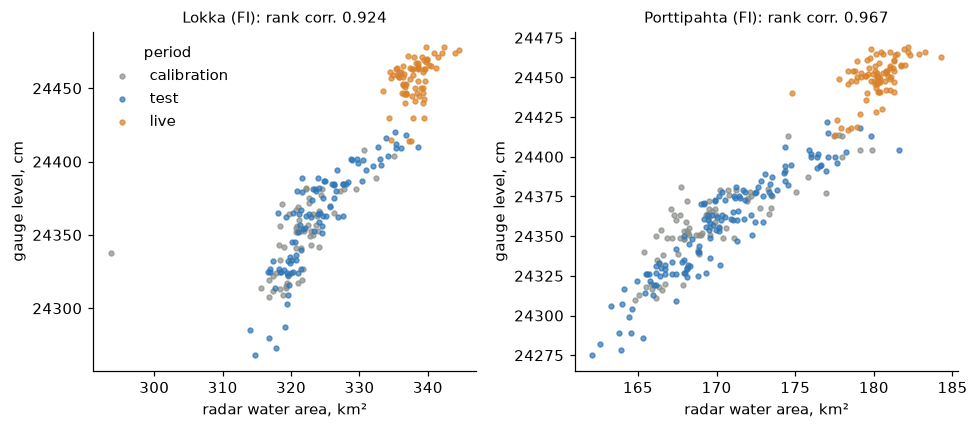

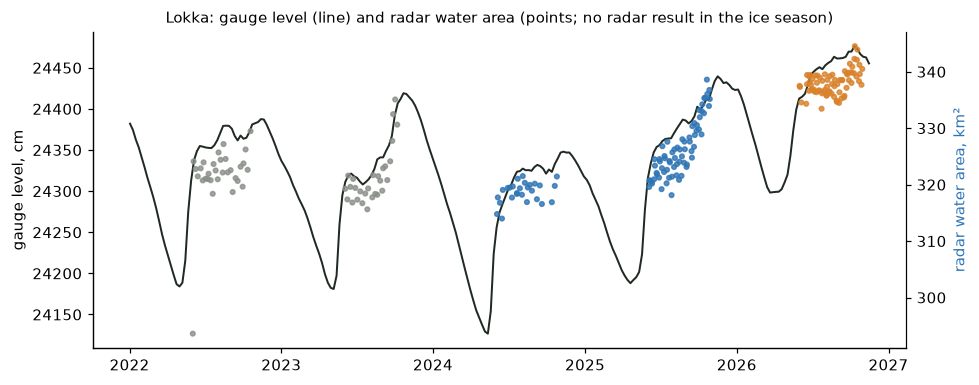

In the test years the level estimated from the radar area was wrong by **19.8 cm** at Lokka and **14.8 cm** at Porttipahta, for a level range of about 111 cm.

In [3]:
#| echo: false
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, wid in zip(axes, ("FI-LOKK", "FI-PORT")):
    scatter(ax, wid)
axes[0].legend(frameon=False, title="period")
plt.tight_layout(); plt.show()
w = W["FI-LOKK"]; x = series("FI-LOKK"); lv = w["level_weekly"]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(pd.to_datetime(lv["date"]), lv["level"], color="#1f2a22", lw=1.3)
ax.set_ylabel("gauge level, cm")
ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
ax2.scatter(x["date"], x["area"], s=9, color=[PCOL[p] for p in x["period"]], alpha=0.8)
ax2.set_ylabel("radar water area, km²", color="#2f75b5")
ax.set_title("Lokka: gauge level (line) and radar water area (points; no radar result in the ice season)", fontsize=10)
plt.tight_layout(); plt.show()
t1, t2 = W["FI-LOKK"]["metrics"]["test"], W["FI-PORT"]["metrics"]["test"]
display(Markdown(f"In the test years the level estimated from the radar area was wrong by **{t1['rmse_cm']} cm** at Lokka and "
                 f"**{t2['rmse_cm']} cm** at Porttipahta, for a level range of about {round(t1['range_cm'])} cm."))

## 4. A partial result: the radar follows the level, but the number is wrong

At Zbiornik Siemianówka (Poland) the radar area follows the level very well in the test years.
But the level estimated from the area is wrong by about one metre. The reason is visible in the chart:
in 2022–2023 (grey) the level moved little, so the line was fitted on a short range. In 2024–2025 (blue) the level
went far below that range, and a straight line does not hold there.

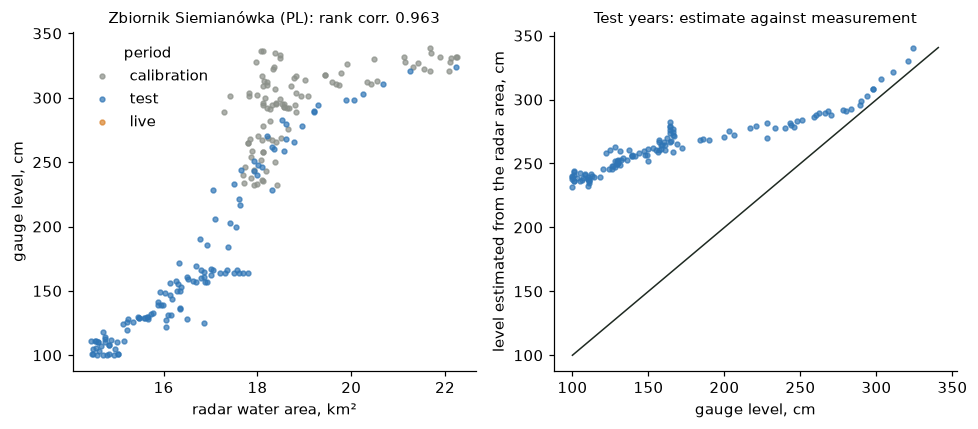

Rank correlation **0.963**, but level error **104.0 cm** for a range of 192.6 cm. By the rules this is only a partial confirmation.

In [4]:
#| echo: false
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
scatter(axes[0], "PL-SIEM")
x = series("PL-SIEM"); q = x[x["period"] == "test"].dropna(subset=["pred"])
axes[1].scatter(q["level"], q["pred"], s=10, color=PCOL["test"], alpha=0.7)
lo, hi = min(q["level"].min(), q["pred"].min()), max(q["level"].max(), q["pred"].max())
axes[1].plot([lo, hi], [lo, hi], color="#1f2a22", lw=1)
axes[1].set_xlabel("gauge level, cm"); axes[1].set_ylabel("level estimated from the radar area, cm")
axes[1].set_title("Test years: estimate against measurement", fontsize=10)
axes[0].legend(frameon=False, title="period")
plt.tight_layout(); plt.show()
t = W["PL-SIEM"]["metrics"]["test"]
display(Markdown(f"Rank correlation **{t['rho']}**, but level error **{t['rmse_cm']} cm** for a range of {t['range_cm']} cm. "
                 f"By the rules this is only a partial confirmation."))

## 5. Where it does not work

On four water bodies the radar area does not follow the level. The clearest case is Vombsjön in Sweden.
I expected a strong signal there, because the level changes by about two metres. But the shores are steep,
so the water area hardly changes, and a 20 m radar pixel cannot see it.

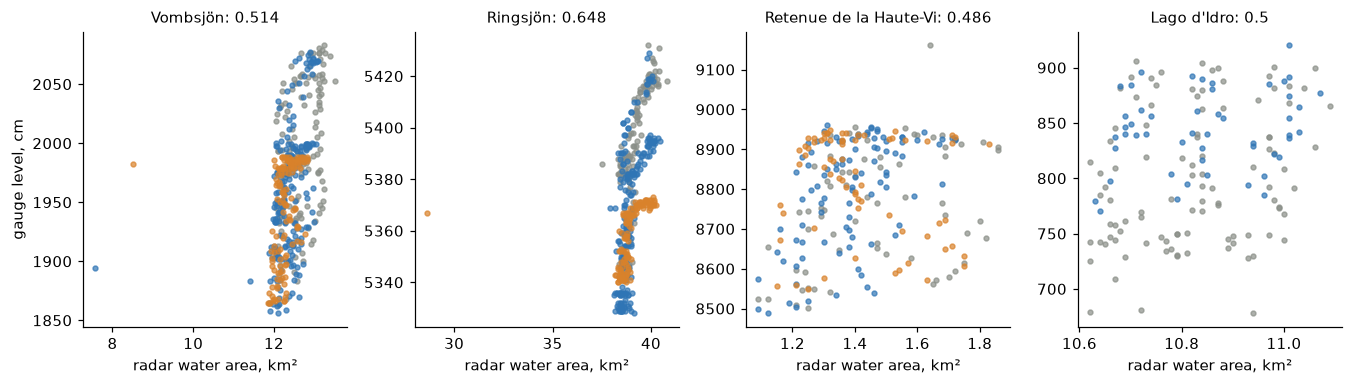

In [5]:
#| echo: false
ids = [w["id"] for w in D["waterbodies"] if w["verdict"] == "not confirmed"][:4]
fig, axes = plt.subplots(1, len(ids), figsize=(3.1 * len(ids), 3.6))
for ax, wid in zip(np.atleast_1d(axes), ids):
    scatter(ax, wid, f"{W[wid]['name'][:22]}: {W[wid]['metrics']['test']['rho']}")
    ax.set_ylabel("")
np.atleast_1d(axes)[0].set_ylabel("gauge level, cm")
plt.tight_layout(); plt.show()

## 6. Control lakes: the method does not invent changes

Three lakes are in the set on purpose: their shores are steep or their level barely moves. There the radar should
show an almost constant area. If it showed large changes, the method would be making them up (wind, plants, noise).

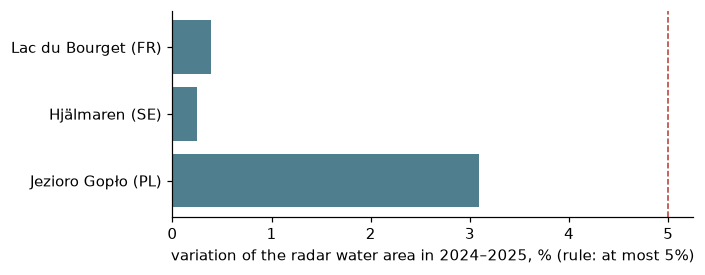

**3 of 3 control lakes are stable.**

In [6]:
#| echo: false
c = [w for w in D["waterbodies"] if w["expected"] == "control"]
fig, ax = plt.subplots(figsize=(6.5, 2.6))
names = [f"{w['name']} ({w['country']})" for w in c]
vals = [100 * w["metrics"]["test"]["cv_area"] for w in c]
ax.barh(names, vals, color=[VCOL[w["verdict"]] for w in c])
ax.axvline(100 * D["rules"]["control_cv"], color="#b23a2e", ls="--", lw=1)
ax.set_xlabel("variation of the radar water area in 2024–2025, % (rule: at most 5%)")
plt.tight_layout(); plt.show()
k = D["summary"]["control"]
display(Markdown(f"**{k['stable']} of {k['n']} control lakes are stable.**"))

## 7. What this means and what it does not

- **Radar can stand in for a gauge only on some water bodies:** large, shallow reservoirs with flat shores.
  That is a useful result, and so is the list of places where it fails.
- **A straight line from area to level is too simple.** It breaks when the level leaves the range it was fitted on.
  The next step is a curve based on the shape of the shore.
- **No result in the ice season.** In Lapland that is half of the year.
- **One live season is not enough.** In 2026 the two Lapland reservoirs score lower. I report it and keep measuring.
- **One lake was removed after the run** (Jezioro Łebsko): its rectangle also covered the Baltic Sea.
  The removal is based on that error, not on its result.
- **Switzerland and Norway are missing:** I found no open gauge history for Switzerland, and Norway needs a key.

**Data:** contains modified Copernicus Sentinel data (Sentinel-1), read from the Microsoft Planetary Computer.
Gauge levels: IMGW-PIB (Poland), SYKE (Finland), SMHI (Sweden), Hub'Eau (France), ARPA Lombardia (Italy).

**Code and live panel:** [github.com/geoworldlook/water-check](https://github.com/geoworldlook/water-check) ·
[live panel](https://geoworldlook.github.io/water-check/showcase/watercheck_panel.html)